# PySaDML - Détection d'anomalies selon le protocole DCASE 2020

Ce notebook reprend le projet de 2022 avec le **protocole officiel du challenge DCASE 2020 Task 2**, pour corriger les problèmes de méthode des notebooks précédents :

| Problème en 2022 | Correction ici |
|---|---|
| Classifieurs supervisés entraînés sur le dossier `test` (le seul qui contient des anomalies), découpé au hasard | Entraînement **uniquement sur `train`** (sons normaux). `test` sert seulement à l'évaluation |
| Accuracy après un seuil choisi en regardant le jeu de test | **AUC et pAUC** (FPR ≤ 0,1) par machine, sans seuil. Le seuil de décision vient de la validation (train) |
| Un seul autoencodeur pour les 6 types de machines | **Un autoencodeur par type de machine** |
| Sortie `sigmoid` sur des données standardisées, spectrogramme tronqué à 4096 valeurs puis remis en 64×64 | Sortie **linéaire**, fenêtres de 5 trames × 128 bandes log-mel (640 valeurs) sur le **signal complet** |
| Signal coupé à 4 s et normalisé par son pic | Signal complet (10 ou 11 s), niveau sonore conservé |
| Jeu de test utilisé comme validation (early stopping) | Validation = 10 % des fichiers de `train` |

La dernière partie mesure aussi ce que valait vraiment l'approche supervisée de 2022, en découpant **par machine** plutôt qu'au hasard.

In [1]:
import os, json, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from include import dcase_baseline as dcase

DATA_ROOT = Path('./../data/dev_data')
FEATURE_DIR = Path('./../data/features_dcase')
MODEL_DIR = Path('./../models/dcase_baseline')

df = dcase.load_dataset_index(DATA_ROOT)
print(df.shape)
df.groupby(['machine_type', 'data_split', 'condition']).size().unstack(fill_value=0)

(30987, 6)


condition                anomaly  normal
machine_type data_split                 
ToyCar       test           1059    1400
             train             0    4000
ToyConveyor  test           1110    2399
             train             0    3000
fan          test           1475     400
             train             0    3675
pump         test            456     400
             train             0    3349
slider       test            890     400
             train             0    2804
valve        test            479     400
             train             0    3291

## 1. Caractéristiques

Paramètres de la référence DCASE 2020 : log-mel à 128 bandes (`n_fft=1024`, `hop_length=512`), puis fenêtres glissantes de 5 trames. Un fichier de 10 s donne 309 fenêtres de 640 valeurs. Les log-mel sont calculés en parallèle et mis en cache dans `data/features_dcase/`.

C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


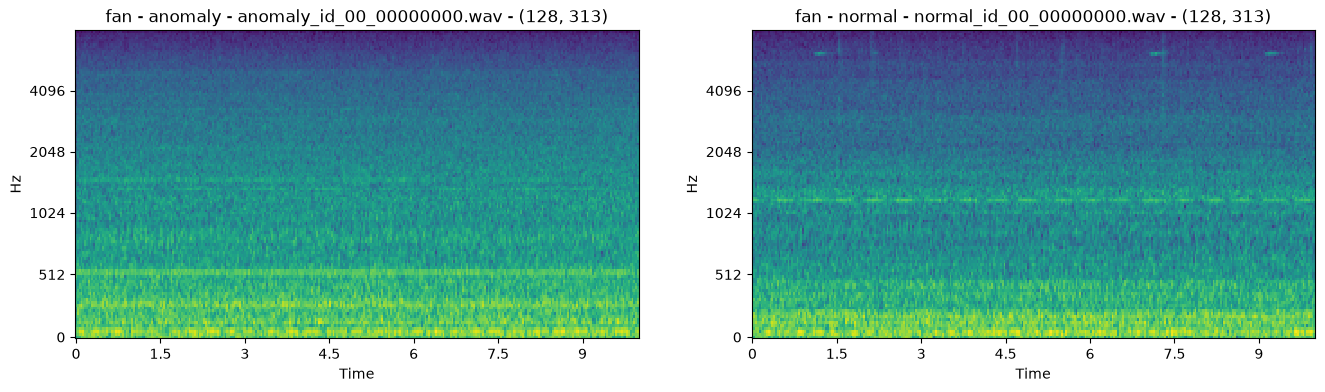

Fenêtres d'un fichier : (309, 640)


In [2]:
example = df[(df.machine_type == 'fan') & (df.data_split == 'test')].groupby('condition').pathname.first()
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
import librosa.display
for ax, (cond, path) in zip(axes, example.items()):
    logmel = dcase.file_to_logmel(path)
    librosa.display.specshow(logmel, sr=dcase.SR, hop_length=dcase.HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax, cmap='viridis')
    ax.set_title(f'fan - {cond} - {Path(path).name} - {logmel.shape}')
plt.show()
print('Fenêtres d\'un fichier :', dcase.file_to_vectors(example['normal']).shape)

## 2. Entraînement : un autoencodeur par type de machine

Architecture de la référence : Dense 128 ×4 → goulot de 8 → Dense 128 ×4 → 640, avec BatchNorm et ReLU, sortie linéaire, perte MSE, Adam. Arrêt précoce sur la validation (10 % des fichiers de `train`). Une epoch couvre 20 % des fenêtres, 40 epochs au plus (8 passages complets, contre 100 dans la référence officielle) : sur CPU, TensorFlow n'utilisant pas le GPU sous Windows, 100 passages prendraient environ 10 h.

Le seuil de décision (pour dire « normal / anormal » dans l'application) est le 90e centile des scores des fichiers de validation : il ne dépend pas du jeu de test.

Les modèles sont sauvegardés dans `models/dcase_baseline/` : si on relance le notebook, ils sont rechargés au lieu d'être réentraînés.

In [3]:
models, infos = {}, {}
for machine_type in dcase.MACHINE_TYPES:
    start = time.time()
    models[machine_type], infos[machine_type] = dcase.train_machine(machine_type, df, FEATURE_DIR, MODEL_DIR, verbose=0)
    info = infos[machine_type]
    print(f"{machine_type:12s} epochs={info['epochs_run']:3d}  val_loss={min(info['history']['val_loss']):.2f}  "
          f"seuil={info['threshold']:.2f}  ({time.time() - start:.0f} s)")

ToyCar       epochs= 40  val_loss=10.44  seuil=11.11  (6 s)


ToyConveyor  epochs= 40  val_loss=10.82  seuil=12.10  (1 s)


fan          epochs= 40  val_loss=9.72  seuil=11.26  (1 s)


pump         epochs= 40  val_loss=10.66  seuil=12.54  (1 s)


slider       epochs= 40  val_loss=10.69  seuil=13.02  (1 s)


valve        epochs= 40  val_loss=10.62  seuil=12.49  (1 s)


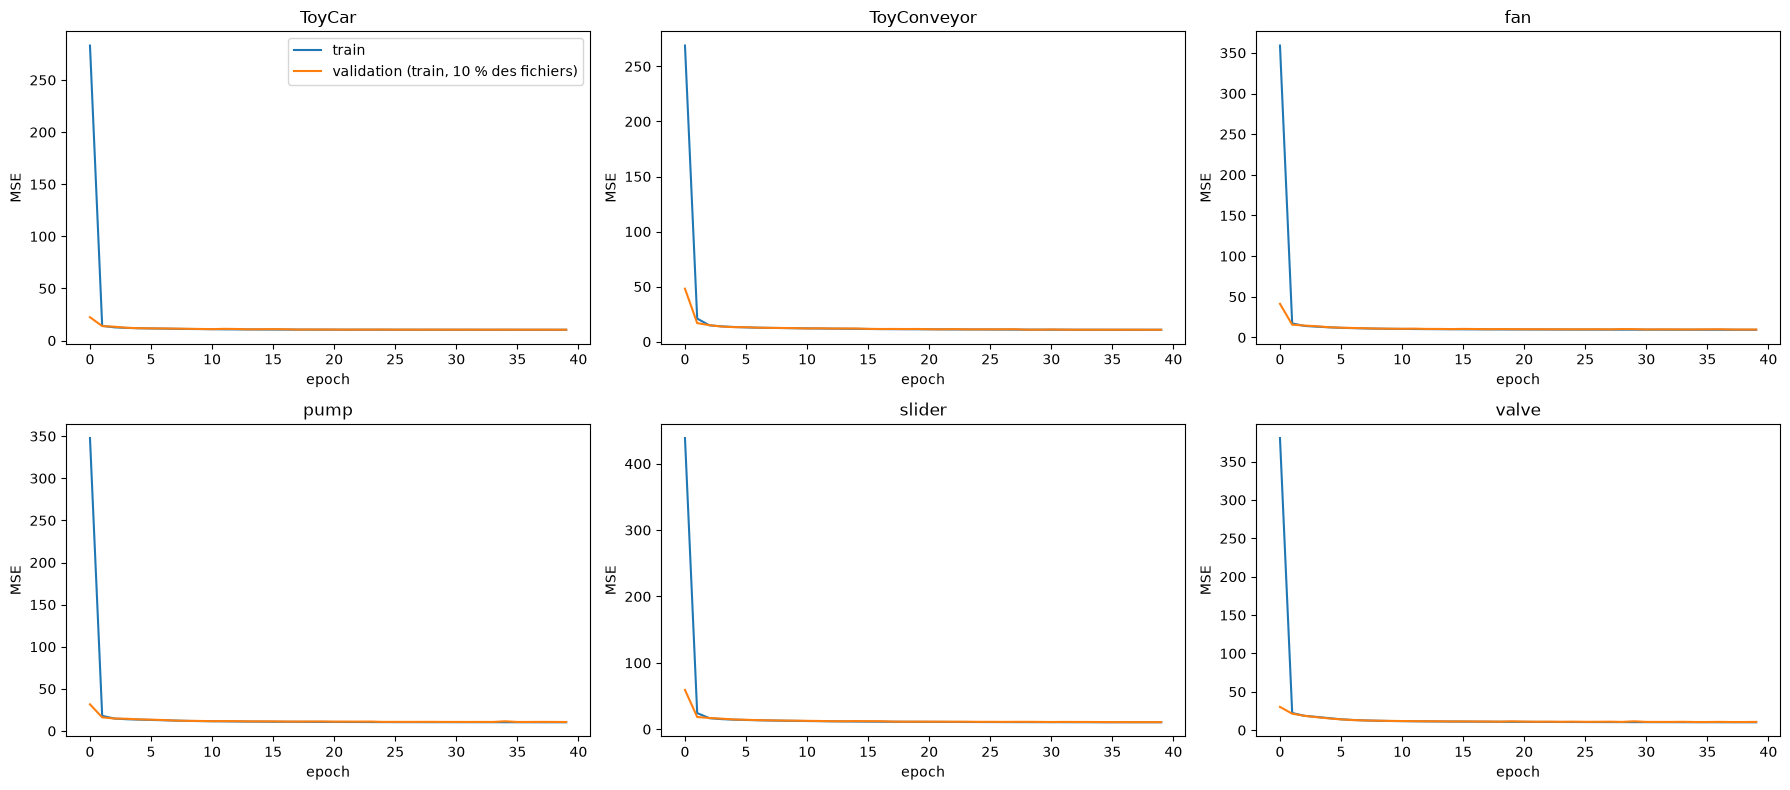

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=False)
for ax, machine_type in zip(axes.ravel(), dcase.MACHINE_TYPES):
    h = infos[machine_type]['history']
    ax.plot(h['loss'], label='train')
    ax.plot(h['val_loss'], label='validation (train, 10 % des fichiers)')
    ax.set_title(machine_type); ax.set_xlabel('epoch'); ax.set_ylabel('MSE')
axes[0, 0].legend()
plt.tight_layout(); plt.show()

## 3. Évaluation sur `test` : AUC et pAUC par machine

C'est la métrique officielle du challenge. L'AUC mesure si les sons anormaux reçoivent un score plus élevé que les sons normaux, **sans choisir de seuil**. La pAUC ne regarde que la zone de faible taux de fausses alarmes (FPR ≤ 0,1), la plus utile en surveillance industrielle.

In [5]:
all_scores, all_metrics = [], []
for machine_type in dcase.MACHINE_TYPES:
    scores_df, metrics_df = dcase.evaluate_machine(machine_type, models[machine_type], infos[machine_type], df, FEATURE_DIR)
    all_scores.append(scores_df); all_metrics.append(metrics_df)
scores = pd.concat(all_scores, ignore_index=True)
metrics = pd.concat(all_metrics, ignore_index=True)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
metrics.to_csv(MODEL_DIR / 'metrics_by_machine_id.csv', index=False)
scores.drop(columns='pathname').to_csv(MODEL_DIR / 'test_scores.csv', index=False)

pd.options.display.float_format = '{:.3f}'.format
metrics

,machine_type,machine_id,AUC,pAUC,precision,recall,F1,n_normal,n_anomaly
0,ToyCar,id_01,0.780,0.645,0.736,0.443,0.553,350,264
1,ToyCar,id_02,0.835,0.726,0.847,0.585,0.692,350,265
2,ToyCar,id_03,0.613,0.536,0.556,0.279,0.372,350,265
3,ToyCar,id_04,0.823,0.651,0.806,0.408,0.541,350,265
4,ToyConveyor,id_01,0.717,0.589,0.570,0.318,0.408,800,400
5,ToyConveyor,id_02,0.603,0.525,0.439,0.223,0.295,800,355
6,ToyConveyor,id_03,0.665,0.546,0.475,0.321,0.383,799,355
7,fan,id_00,0.556,0.494,0.830,0.204,0.327,100,407
8,fan,id_02,0.686,0.541,0.900,0.125,0.220,100,359
9,fan,id_04,0.574,0.533,0.868,0.170,0.284,100,348


In [6]:
summary = dcase.summarize(metrics)
summary.to_csv(MODEL_DIR / 'metrics_summary.csv')
summary

,AUC,pAUC,precision,recall,F1
machine_type,,,,,
ToyCar,0.763,0.640,0.736,0.429,0.540
ToyConveyor,0.662,0.553,0.494,0.287,0.362
fan,0.634,0.526,0.874,0.162,0.272
pump,0.712,0.603,0.779,0.358,0.485
slider,0.787,0.610,0.811,0.474,0.580
valve,0.553,0.504,0.557,0.092,0.157
Moyenne,0.685,0.573,0.709,0.300,0.399


Pour comparaison, les AUC moyennes publiées pour la référence officielle DCASE 2020 sur ce jeu de développement sont d'environ : ToyCar 0,79 ; ToyConveyor 0,73 ; fan 0,66 ; pump 0,73 ; slider 0,85 ; valve 0,66.

Les colonnes `precision`, `recall` et `F1` utilisent le seuil fixé sur la validation. Elles dépendent de ce seuil, contrairement à l'AUC.

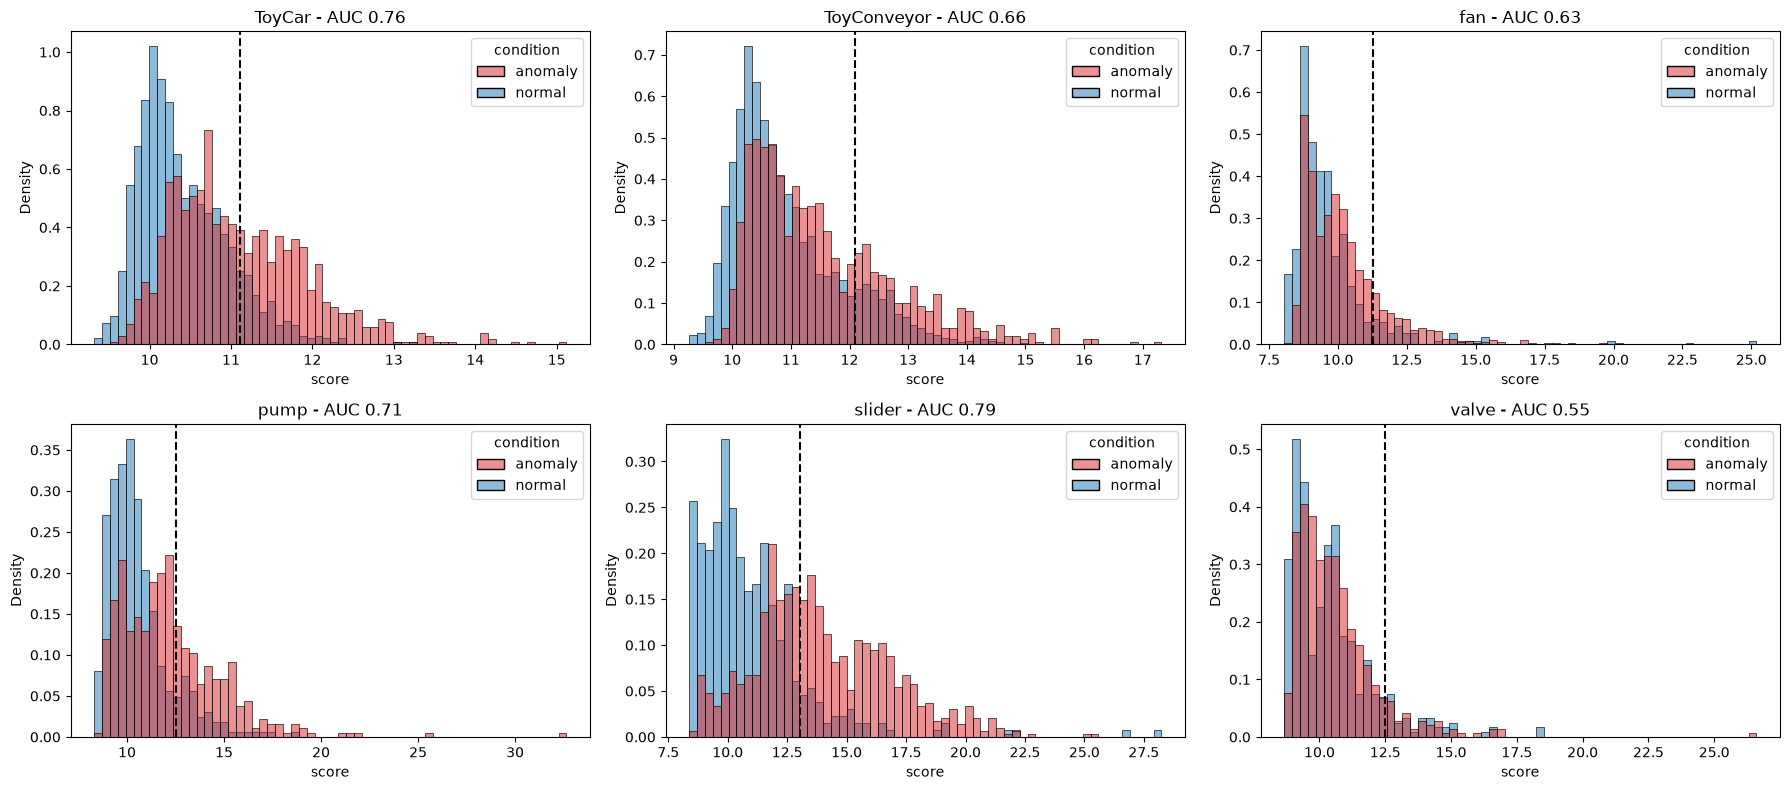

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, machine_type in zip(axes.ravel(), dcase.MACHINE_TYPES):
    s = scores[scores.machine_type == machine_type]
    sns.histplot(data=s, x='score', hue='condition', bins=60, stat='density', common_norm=False, ax=ax,
                 palette={'normal': 'tab:blue', 'anomaly': 'tab:red'})
    ax.axvline(infos[machine_type]['threshold'], color='k', ls='--', label='seuil (validation)')
    ax.set_title(f"{machine_type} - AUC {summary.loc[machine_type, 'AUC']:.2f}")
plt.tight_layout(); plt.show()

## 4. Ce que valait vraiment l'approche supervisée de 2022

En 2022, les classifieurs « normal / anormal » étaient entraînés sur 80 % du dossier `test` tiré **au hasard** et évalués sur les 20 % restants (86 à 90 % d'accuracy). Les mêmes machines se retrouvaient alors des deux côtés, et le type de machine suffisait à deviner une bonne partie des réponses.

On compare ici, pour chaque type de machine, deux découpages du dossier `test` avec le même classifieur (forêt aléatoire sur la moyenne et l'écart-type du log-mel de chaque fichier) :

- **au hasard** (comme en 2022), en validation croisée à 4 plis ;
- **par machine** : on entraîne sur les autres identifiants et on teste sur un identifiant jamais vu (`GroupKFold`). C'est la situation réelle : détecter une anomalie sur une machine qui n'a pas servi à l'entraînement.

Cette approche reste une borne « avec étiquettes d'anomalies », que DCASE n'autorise pas.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

rows = []
for machine_type in dcase.MACHINE_TYPES:
    test_df = df[(df.machine_type == machine_type) & (df.data_split == 'test')].reset_index(drop=True)
    logmels = dcase.extract_logmels(test_df, FEATURE_DIR / f'{machine_type}_test.npy')
    X = np.concatenate([logmels.mean(axis=2), logmels.std(axis=2)], axis=1)
    y = (test_df.condition == 'anomaly').astype(int).values
    clf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0)
    p_random = cross_val_predict(clf, X, y, cv=StratifiedKFold(4, shuffle=True, random_state=0), method='predict_proba')[:, 1]
    p_group = cross_val_predict(clf, X, y, cv=GroupKFold(test_df.machine_id.nunique()), groups=test_df.machine_id, method='predict_proba')[:, 1]
    for machine_id in sorted(test_df.machine_id.unique()):
        m = (test_df.machine_id == machine_id).values
        rows.append({'machine_type': machine_type, 'machine_id': machine_id,
                     'AUC découpage au hasard': roc_auc_score(y[m], p_random[m]),
                     'AUC machine jamais vue': roc_auc_score(y[m], p_group[m])})
supervised = pd.DataFrame(rows)
supervised.to_csv(MODEL_DIR / 'supervised_split_comparison.csv', index=False)

comparison = supervised.groupby('machine_type')[['AUC découpage au hasard', 'AUC machine jamais vue']].mean()
comparison['AUC autoencodeur (train seul)'] = summary['AUC']
comparison.loc['Moyenne'] = comparison.mean()
comparison

,AUC découpage au hasard,AUC machine jamais vue,AUC autoencodeur (train seul)
machine_type,,,
ToyCar,0.985,0.953,0.763
ToyConveyor,0.921,0.547,0.662
fan,0.907,0.538,0.634
pump,0.961,0.706,0.712
slider,0.982,0.588,0.787
valve,0.974,0.580,0.553
Moyenne,0.955,0.652,0.685


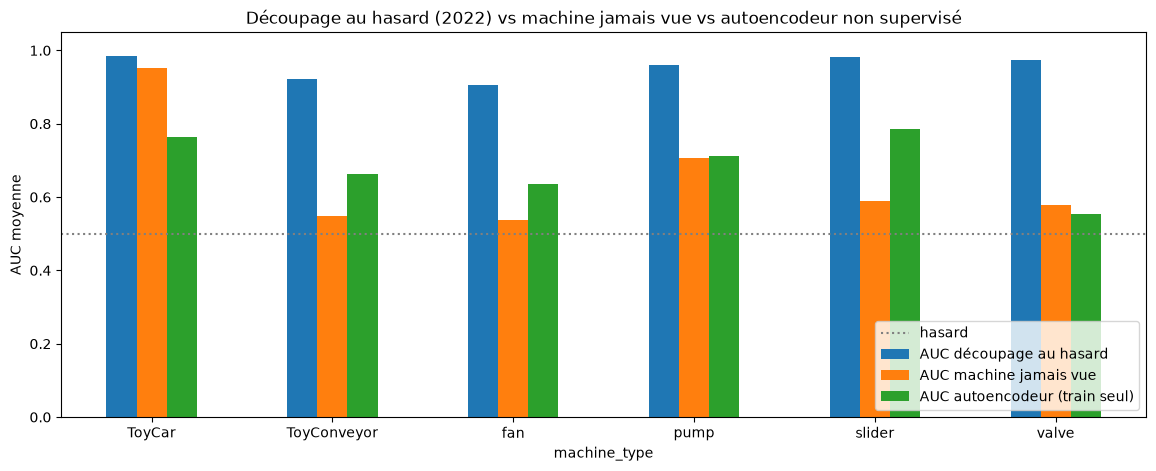

In [9]:
ax = comparison.drop('Moyenne').plot.bar(figsize=(14, 5), rot=0)
ax.axhline(0.5, color='grey', ls=':', label='hasard')
ax.set_ylabel('AUC moyenne'); ax.set_ylim(0, 1.05); ax.legend(loc='lower right')
plt.title('Découpage au hasard (2022) vs machine jamais vue vs autoencodeur non supervisé')
plt.show()

## 6. Pistes d'amélioration, en particulier pour valve

L'autoencodeur est presque au niveau du hasard sur valve (AUC 0,55). On teste ici deux pistes, sur toutes les machines pour vérifier qu'une amélioration sur valve ne dégrade pas les autres :

1. **Le score du fichier.** La référence fait la moyenne de l'erreur sur les ~310 fenêtres d'un fichier. Si l'anomalie ne dure qu'une partie du fichier, la moyenne la dilue. On compare avec des scores qui donnent plus de poids aux passages mal reconstruits : centile 90, centile 99 et maximum de l'erreur par fenêtre. Aucun réentraînement n'est nécessaire.
2. **Un modèle par machine** (identifiant) au lieu d'un modèle par type de machine. Les 4 vannes du jeu ne sonnent pas forcément pareil, et un modèle unique doit apprendre toutes leurs variantes « normales ».

**Précaution.** Ces variantes sont comparées sur le dossier `test` du jeu de développement : c'est son rôle dans DCASE, mais choisir la meilleure variante sur ce même jeu rend son score un peu optimiste. Une confirmation sur le jeu d'évaluation DCASE (`eval_data`, absent ici) serait nécessaire.

### 6.1 Agréger autrement les erreurs par fenêtre

In [10]:
def auc_by_aggregation(errors_by_file, test_df):
    rows = []
    for agg_name, agg in dcase.AGGREGATIONS.items():
        s = test_df.assign(score=agg(errors_by_file))
        for machine_id, g in s.groupby('machine_id'):
            y = (g.condition == 'anomaly').astype(int)
            rows.append({'machine_type': g.machine_type.iloc[0], 'machine_id': machine_id, 'score': agg_name,
                         'AUC': roc_auc_score(y, g.score), 'pAUC': roc_auc_score(y, g.score, max_fpr=dcase.MAX_FPR)})
    return rows

rows = []
for machine_type in dcase.MACHINE_TYPES:
    test_df = df[(df.machine_type == machine_type) & (df.data_split == 'test')].reset_index(drop=True)
    logmels = dcase.extract_logmels(test_df, FEATURE_DIR / f'{machine_type}_test.npy')
    rows += auc_by_aggregation(dcase.window_errors(models[machine_type], logmels), test_df)
agg_type = pd.DataFrame(rows)

agg_table = agg_type.pivot_table(index='machine_type', columns='score', values='AUC', aggfunc='mean')[list(dcase.AGGREGATIONS)]
agg_table.loc['Moyenne'] = agg_table.mean()
agg_table

score,moyenne,centile 90,centile 99,maximum
machine_type,,,,
ToyCar,0.763,0.727,0.646,0.608
ToyConveyor,0.662,0.622,0.575,0.562
fan,0.634,0.613,0.587,0.574
pump,0.712,0.695,0.670,0.663
slider,0.787,0.853,0.838,0.820
valve,0.553,0.623,0.705,0.682
Moyenne,0.685,0.689,0.670,0.651


### 6.2 Un autoencodeur par machine (identifiant)

Même architecture, mêmes paramètres et même budget d'entraînement par fenêtre ; seules les données changent (les fichiers `train` d'une seule machine). Les modèles sont sauvegardés dans `models/dcase_baseline/par_id/`.

In [11]:
PER_ID_DIR = MODEL_DIR / 'par_id'
rows, id_infos = [], {}
start = time.time()
for machine_type in dcase.MACHINE_TYPES:
    test_type = df[(df.machine_type == machine_type) & (df.data_split == 'test')].reset_index(drop=True)
    logmels_type = dcase.extract_logmels(test_type, FEATURE_DIR / f'{machine_type}_test.npy')
    for machine_id in sorted(test_type.machine_id.unique()):
        model_id, id_infos[(machine_type, machine_id)] = dcase.train_machine(
            machine_type, df, FEATURE_DIR, PER_ID_DIR, machine_id=machine_id, verbose=0)
        mask = (test_type.machine_id == machine_id).values
        rows += auc_by_aggregation(dcase.window_errors(model_id, logmels_type[mask]),
                                   test_type[mask].reset_index(drop=True))
print(f'{len(id_infos)} modèles ({time.time() - start:.0f} s)')
agg_id = pd.DataFrame(rows)

id_table = agg_id.pivot_table(index='machine_type', columns='score', values='AUC', aggfunc='mean')[list(dcase.AGGREGATIONS)]
id_table.loc['Moyenne'] = id_table.mean()
id_table

C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (15 outputs left out)

C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\Users\guidy\Documents\GitHub\PySaDML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23 modèles (1015 s)


score,moyenne,centile 90,centile 99,maximum
machine_type,,,,
ToyCar,0.778,0.710,0.594,0.559
ToyConveyor,0.644,0.596,0.542,0.530
fan,0.621,0.605,0.586,0.578
pump,0.699,0.694,0.685,0.681
slider,0.715,0.754,0.713,0.702
valve,0.484,0.502,0.480,0.469
Moyenne,0.657,0.643,0.600,0.586


### 6.3 Synthèse

In [12]:
results = pd.concat([agg_type.assign(modèle='par type'), agg_id.assign(modèle='par identifiant')])
results.to_csv(MODEL_DIR / 'experiences_agregation_par_id.csv', index=False)

summary_exp = results.groupby(['modèle', 'score', 'machine_type'])[['AUC', 'pAUC']].mean().reset_index()
auc_exp = summary_exp.pivot_table(index='machine_type', columns=['modèle', 'score'], values='AUC')
auc_exp.loc['Moyenne'] = auc_exp.mean()
pauc_exp = summary_exp.pivot_table(index='machine_type', columns=['modèle', 'score'], values='pAUC')
pauc_exp.loc['Moyenne'] = pauc_exp.mean()
print('AUC'); display(auc_exp.round(3))
print('pAUC'); display(pauc_exp.round(3))

AUC


modèle       par identifiant                              par type             \
score             centile 90 centile 99 maximum moyenne centile 90 centile 99   
machine_type                                                                    
ToyCar                 0.710      0.594   0.559   0.778      0.727      0.646   
ToyConveyor            0.596      0.542   0.530   0.644      0.622      0.575   
fan                    0.605      0.586   0.578   0.621      0.613      0.587   
pump                   0.694      0.685   0.681   0.699      0.695      0.670   
slider                 0.754      0.713   0.702   0.715      0.853      0.838   
valve                  0.502      0.480   0.469   0.484      0.623      0.705   
Moyenne                0.643      0.600   0.586   0.657      0.689      0.670   

modèle                        
score        maximum moyenne  
machine_type                  
ToyCar         0.608   0.763  
ToyConveyor    0.562   0.662  
fan            0.574   0.634  
pump           0.663   0.712  
slider         0.820   0.787  
valve          0.682   0.553  
Moyenne        0.651   0.685

pAUC


modèle       par identifiant                              par type             \
score             centile 90 centile 99 maximum moyenne centile 90 centile 99   
machine_type                                                                    
ToyCar                 0.553      0.504   0.510   0.641      0.593      0.527   
ToyConveyor            0.515      0.499   0.500   0.539      0.535      0.501   
fan                    0.544      0.534   0.532   0.557      0.512      0.503   
pump                   0.581      0.584   0.581   0.581      0.599      0.579   
slider                 0.610      0.584   0.559   0.592      0.639      0.609   
valve                  0.528      0.505   0.500   0.502      0.522      0.524   
Moyenne                0.555      0.535   0.530   0.569      0.566      0.540   

modèle                        
score        maximum moyenne  
machine_type                  
ToyCar         0.514   0.640  
ToyConveyor    0.502   0.553  
fan            0.506   0.526  
pump           0.582   0.603  
slider         0.585   0.610  
valve          0.519   0.504  
Moyenne        0.535   0.573

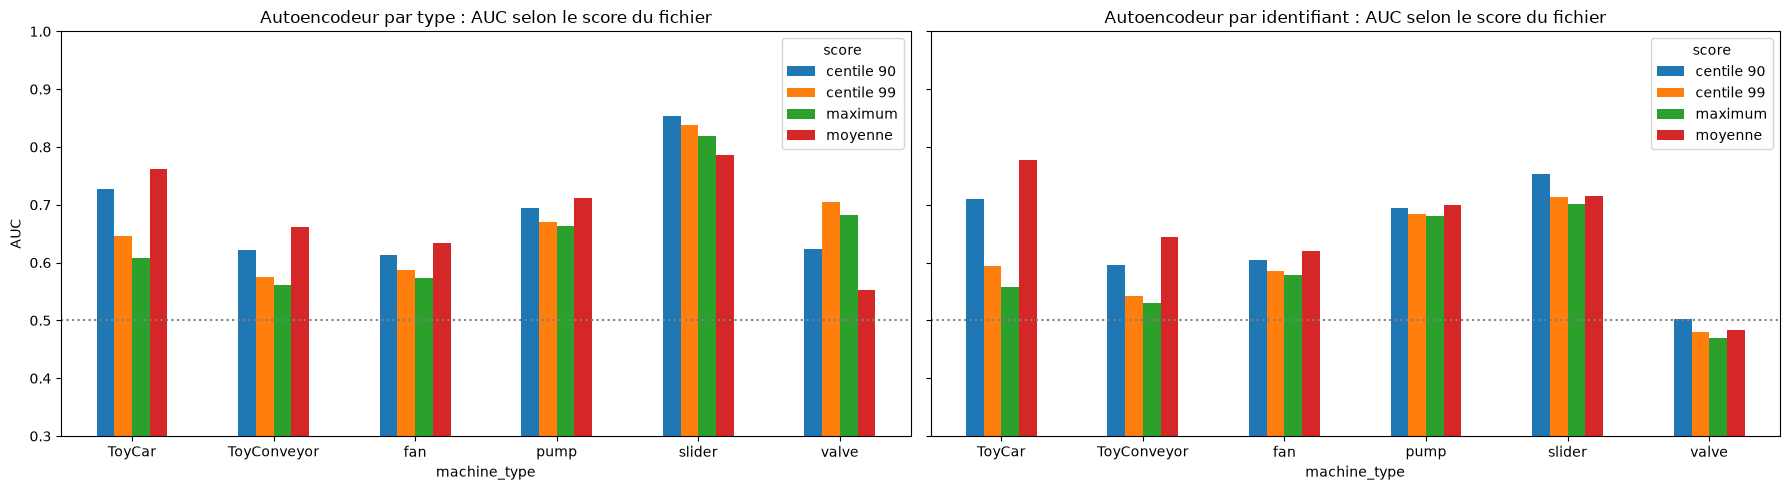

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, modele in zip(axes, ['par type', 'par identifiant']):
    auc_exp[modele].drop('Moyenne').plot.bar(ax=ax, rot=0)
    ax.axhline(0.5, color='grey', ls=':')
    ax.set_title(f'Autoencodeur {modele} : AUC selon le score du fichier'); ax.set_ylim(0.3, 1.0); ax.set_ylabel('AUC')
plt.tight_layout(); plt.show()

In [14]:
# valve en détail, machine par machine
results[results.machine_type == 'valve'].pivot_table(index='machine_id', columns=['modèle', 'score'], values='AUC').round(3)

modèle     par identifiant                              par type             \
score           centile 90 centile 99 maximum moyenne centile 90 centile 99   
machine_id                                                                    
id_00                0.365      0.082   0.071   0.404      0.633      0.768   
id_02                0.638      0.720   0.710   0.580      0.670      0.750   
id_04                0.563      0.638   0.618   0.503      0.682      0.789   
id_06                0.442      0.482   0.478   0.448      0.508      0.511   

modèle                      
score      maximum moyenne  
machine_id                  
id_00        0.746   0.563  
id_02        0.706   0.572  
id_04        0.766   0.608  
id_06        0.511   0.469

## 7. Conclusion

- **Le score de 2022 venait surtout du protocole.** Avec un découpage au hasard du dossier `test`, la même approche supervisée obtient une AUC moyenne de 0,955. Sur une machine jamais vue, elle tombe à 0,652 : à part ToyCar (0,95), elle reconnaît surtout les machines déjà vues, pas l'anomalie.
- **L'autoencodeur par type de machine, entraîné sans aucune anomalie, atteint une AUC moyenne de 0,685** (pAUC 0,573), un peu en dessous de la référence officielle (environ 0,74). Le budget d'entraînement est plus court (8 passages contre 100), mais la perte de validation plafonnait déjà.
- **valve : le score du fichier compte plus que le modèle.** En remplaçant la moyenne de l'erreur par son centile 99, l'AUC de valve passe de 0,553 à 0,705 (slider : de 0,787 à 0,853 avec le centile 90). C'est cohérent avec des anomalies localisées dans le temps, que la moyenne dilue. Mais ce n'est pas une règle générale : ToyCar et ToyConveyor perdent avec ces scores, la moyenne sur les 6 machines ne bouge presque pas (0,685 → 0,689), et la pAUC de valve reste proche du hasard (0,52). valve id_06 reste au hasard quel que soit le score.
- **Un modèle par machine (identifiant) fait moins bien** (AUC moyenne 0,657, valve 0,48) : chaque modèle apprend sur environ quatre fois moins de fichiers.
- **Ce qu'on peut en retenir** : choisir le score par type de machine (moyenne, centile 90 pour slider, centile 99 pour valve) donnerait une AUC moyenne d'environ 0,72. Ce chiffre est optimiste, car ce choix a été fait en regardant le dossier `test` ; il faudrait le confirmer sur le jeu d'évaluation DCASE avant de l'adopter. L'application garde donc la règle de la référence (moyenne).
- Le seuil de décision vient de la validation : il donne une bonne précision (0,71) mais un rappel faible (0,30). Un seuil plus bas détecterait plus d'anomalies au prix de plus de fausses alarmes.
